# <div align="center">  Assignment 1: Power Spectral Density Estimation </div>

## <div align="center"> Deadline: See Module’s Brightspace </div>

**Note:** This assignment is worth **15%** towards the total module grade.

# Description
You are given an audio file that contains a chord (played three times) recorded from a piano. A chord, in any musical instrument, consists of two or more (usually three or more) notes (also called “pitches”) that are heard as if sounding simultaneously. Some background on piano notes is given in the Appendix at the end of the file. Your task is to detect all the notes in the given chord. To do this, a possible method is to estimate the power spectral density (PSD) of the signal.

# Read in data
Download the audio file provided in the Brighspce portal for this assignment (i.e. the "PianoChord.wav"). You can play this audio file using any media player available to you to hear the chord. To read the audio file in Python, you can use the following code

In [1]:
from scipy.io import wavfile
Fs, data = wavfile.read('PianoChord.wav')
print("The sampling rate is %f" %Fs) # print out the sampling rate of the audio file

The sampling rate is 48000.000000


/tmp/ipykernel_11921/1046975494.py:2: WavFileWarning: Chunk (non-data) not understood, skipping it.
  Fs, data = wavfile.read('PianoChord.wav')


The following code cell plots the waveform (i.e. the time domain representation) of the sound.

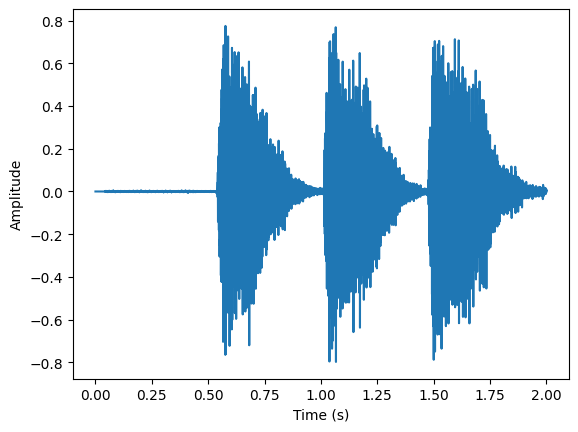

In [2]:
import matplotlib.pyplot as plt
import numpy as np
N = data.size ## number of samples
plt.plot(np.arange(N)/Fs, data)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()

# TASK 1: Periodogram
Write a Python program to compute and plot the periodogram to estimate the PSD of the given  signal and give your comments. Make your observations based on the obtained periodogram

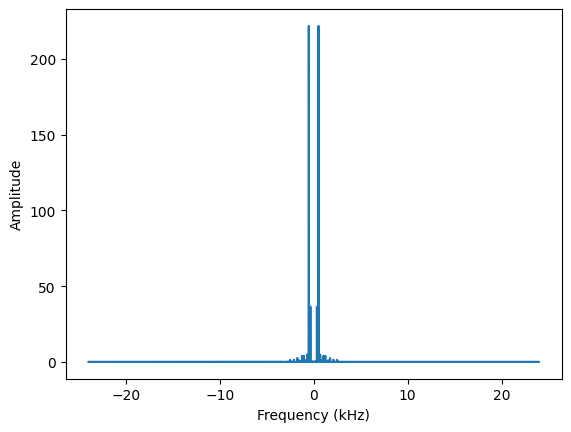

In [3]:
X = np.fft.fft(data) # Obtain the DFT of x

X_mag = np.abs(X) # Obtain the magnitude of each frequency bin. Since the result of fft is complex.

S_xx = (1/N) * (X_mag**2) # Periodogram formula 
freqs = np.fft.fftfreq(N, 1/Fs)

plt.plot(freqs/1000, S_xx)
plt.xlabel('Frequency (kHz)')
plt.ylabel('Amplitude')
plt.show()

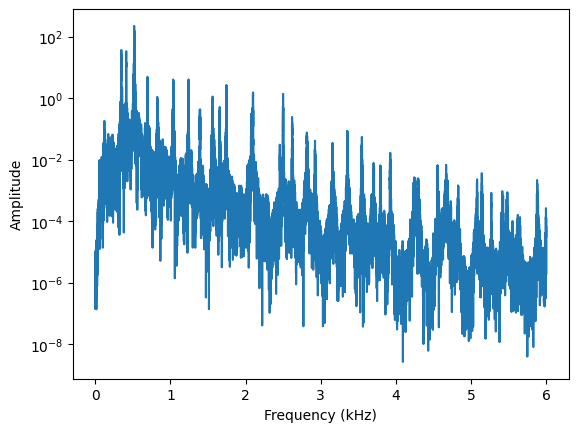

In [4]:
#Re-plot it to focus on relevant data
plt.semilogy(freqs[:int(N/8)]/1000, S_xx[:int(N/8)])
plt.xlabel('Frequency (kHz)')
plt.ylabel('Amplitude')
plt.show()

## Task 1 Observations
We have 1 peak at 0.5kHz.
Since the signal is real, its DFT is symmetrical about 0Hz, so we can discard the negative frequencies.

# TASK 2: Welch's method
Write a Python program that implements Welch’s method to estimate the PSD of the given chord and identify all the notes present in the signal. Plot the estimated PSD and compare it with the estimated PSD obtained in Task 2. In your implementation, address the following requirements
1. Provide an explanation on a proper choice for the size of the FFT for each segment, considering the frequency resolution required to distinguish the musical notes.
2. Ensure that all samples of the signal are included in the PSD estimation.
3. Investigate and discuss the impact of changing the number of samples per segment and the amount of overlapping on the performance.

/tmp/ipykernel_11921/3513338966.py:5: WavFileWarning: Chunk (non-data) not understood, skipping it.
  Fs, data = wavfile.read('PianoChord.wav')


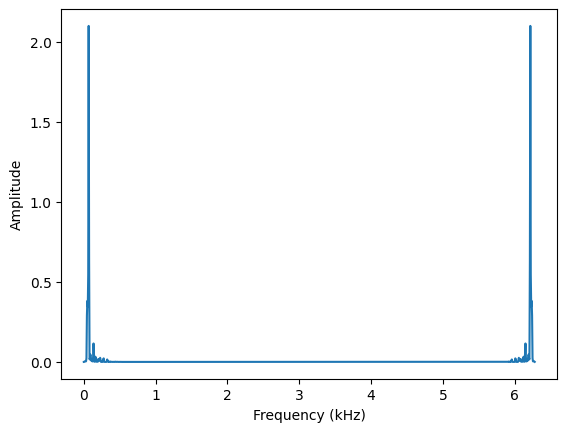

In [ ]:
# Welch's method
# overlapping K sectiosn of length L
# each section multiplied by a hanning window
# 1. Choose FFT size ? power of 2.. need enough resolution to pick up on all low-notes
Fs, data = wavfile.read('PianoChord.wav')

L = int(1024)
window = np.hanning(L)
k = int(0)
S_xx_Welch = np.zeros(L//2 + 1)
nSegments = 0
while k < N - L:
    # current_segment = data[int(k):int(k+L)]
    # current_segment *= window these 2 lines were modifying the data in-place
    current_segment = data[int(k):int(k+L)] * window
    current_segment_fft = np.fft.rfft(current_segment)
    current_segment_fft_mag = np.abs(current_segment_fft) # NEED TO NORMALISE WINDOW EFFECT MAYBE ? 
    current_segment_periodogram = (1/L) * (current_segment_fft_mag**2)
    S_xx_Welch += current_segment_periodogram # accumulate the periodogram
    nSegments += 1
    k += L/2 # Move to the next overlapping segment

S_xx_Welch /= nSegments

freqs_welch = 2*np.pi/L * np.arange(L)
plt.plot(freqs_welch, S_xx_Welch)
plt.xlabel('Frequency (kHz)')
plt.ylabel('Amplitude')
plt.show()

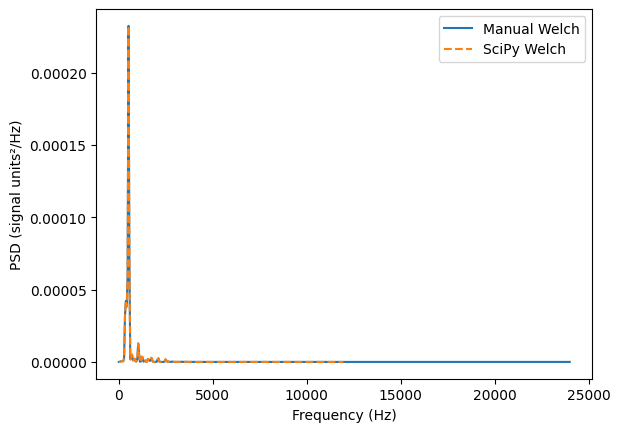

In [ ]:
import matplotlib.pyplot as plt
from scipy import signal

# Reload data from the WAV file first!
Fs = 48000
x = np.asarray(data, dtype=float).copy()

L = 1024
hop = L // 2
window = np.hanning(L)

# Pad so the last window ends exactly at the padded signal's end.
padding = max(0, L - len(x))
padding += (-(len(x) + padding - L)) % hop
x = np.pad(x, (0, padding))

S_xx_Welch = np.zeros(L // 2 + 1)
nSegments = 0

for k in range(0, len(x) - L + 1, hop):
    segment = x[k:k+L] * window  # Does not change x

    X = np.fft.rfft(segment)
    P = np.abs(X)**2 / (Fs * np.sum(window**2))

    P[1:-1] *= 2  # One-sided PSD; L is even

    S_xx_Welch += P
    nSegments += 1

S_xx_Welch /= nSegments
freqs = np.fft.rfftfreq(L, d=1/Fs)

# Benchmark with exactly the same data and settings.
f_builtin, P_builtin = signal.welch(
    x,
    fs=Fs,
    window=window,
    nperseg=L,
    noverlap=L-hop,
    nfft=L,
    detrend=False,
    scaling="density"
)

plt.plot(freqs, S_xx_Welch, label="Manual Welch")
plt.plot(f_builtin, P_builtin, "--", label="SciPy Welch")
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (signal units²/Hz)")
plt.legend()
plt.show()

# TASK 3: Compare with built-in function welch in Scipy's package
The SciPy package provides a built-in function "welch" for estimating the power spectral density of a signal using Welch’s method.  You can find the documentation of the welch function here: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html#scipy.signal.welch. Compare your method with this built-in function.

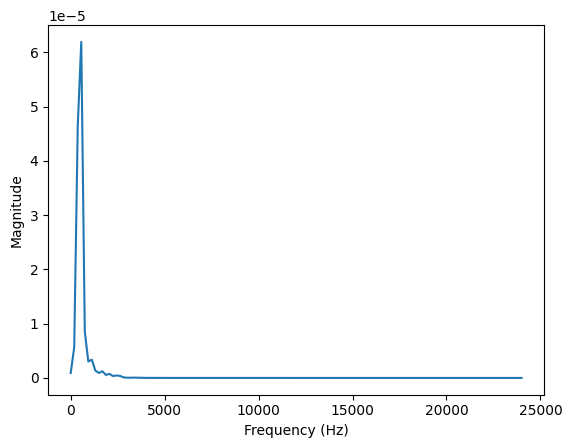

In [6]:
from scipy import signal
f, Sxx_builtin_Welch = signal.welch(data, 48000)
plt.plot(f, Sxx_builtin_Welch)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.show()

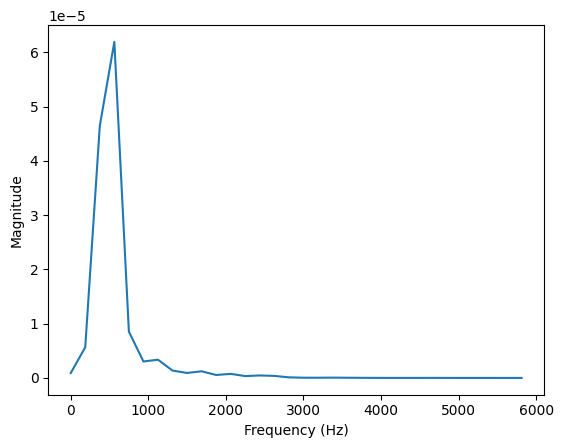

In [7]:
num_welch = len(Sxx_builtin_Welch)
plt.plot(f[:num_welch//4], Sxx_builtin_Welch[:num_welch//4])
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.show()

# Rules
- You are NOT allowed to use the built-in “welch” function mentioned above as part of your method. However you can use it for benchmarking purposes.

- You cannot use any other audio processing or note detection software.

- You  can use standard signal processing commands such as those performing correlations, convolutions, filtering and FFTs if needed. If any doubt, you need to contact the coordinator for clarification.

- You can display intermediate results (data and plots) on screen to see how your algorithm is progressing.

- You are allowed to use AI to complete the assignment. However, you need to disclose the AI tool and how it is used to help you complete the assignment.

# Report & Submission Guidelines
You are asked to submit your Jupyter notebook with your name (**firstname_lastname**) as filename  to the Brightspace submission portal for this assignment. Your report should be all your own work.


STUDENTS MUST WORK INDEPENDENTLY. PROGRAMS WILL BE EXAMINED FOR EVIDENCE OF COPYING. COPYING OR ALLOWING YOUR WORK TO BE COPIED WILL RESULT IN ZERO MARKS BEING ALLOCATED FOR THE ASSIGNMENT.


# Grading Scheme

1. The code is efficient, which basically means you need to treat a variable as a vector or matrix when possible.

2. The code is well commented. 

3. All the plots/figures should be labelled properly, including a proper unit for each quantity shown.

4. Every step of your proposed method needs to be clearly explained. For example, if you set some parameters in your method to a specific numeric value, you also need to explain why this specific value is a good choice.

5. A good set of comments on the obtained results and make good reference to the related theory.

6. Be able to explain the difference (if any) between your implementation and other the corresponding built-in functions.


# Appendix
When a particular note is played on a musical instrument not only is the fundamental frequency (tone) generated but also higher harmonics of the fundamental, i.e., pure tones at the frequencies $2f, 3f, 4f,\ldots$ These harmonics give the instrument a richer sound. For example the DFT of a piano middle C (commonly known as “C4”) is illustrated in the following figure.
<p align="center">
    <img src="FFTC4.png">
</p>

As the frequency of C4 is ≈ 261 Hz, we can see that the DFT shown in the figure above has peaks at 261 Hz and at higher harmonics. The frequencies of a standard (i.e. 88-key) piano can be found at the following link: [https://en.wikipedia.org/wiki/Piano_key_frequencies](https://en.wikipedia.org/wiki/Piano_key_frequencies).